# Run sets: consecutive runs as one timeline

Some runs continue one another (e.g. **r562 → r563 → r564**). Here each set is one timeline: train 8 of r562 is
followed by train 0 of r563, and so on. (`bubble_runs_analysis.ipynb` instead compares the same train number
across runs.)

A set is a results folder named `<name>_set` (from `bubble_inference.ipynb`), whose runs are taken from the frame
names inside it, or an explicit list of runs in `RUN_SETS`.

| section | question |
|---|---|
| 2 timeline | bubble count (and size, coverage, area, ...) through every train of every run, by train and by time |
| 3 decay fits | exponential decay of the bubble count after each scan, one fit per run over trains you choose |
| 4 run boundaries | does the next run continue where the previous one ended, or is there a jump? |
| 5 runs within the set | does each run evolve the same way (relative to its own first train)? |
| 6 size distribution | the size distribution through the whole set |
| 7 trends | the trend over the whole set |
| **8 findings** | **text box to paste back to Claude** |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
import bubble_stats as bst
import bubble_compare as bc
import bubble_sets as bset

bst.style()
F = bc.Findings()

## CONFIG

In [2]:
RESULTS_ROOT = "results"
RUN_SETS = {"r563_set": bset.runs_in_folder("results/r563_set")}   # None = every `<name>_set` folder; or a list:
                               # {"r562-r564": ["r562", "r563", "r564"]} (runs in time order; the key must match a
                               # _set folder to read from it; other runs are read from results/<run>/)
FRAME_IDX = 10                 # frame number used in every train
REVIEWED_ONLY = False
IN_ANALYSIS_ONLY = True
EXPORT_MISSING = True          # write bubbles.csv from the shape files where it is missing (needs the .tif copies)

# timestamps: every plot is drawn against the train (in order) and against time
TRAIN_SECONDS = 15.0           # time between trains within a run
RUN_START_S = {"r562": 0, "r563": 149, "r564": 286,}               # start of train 0 of each run, in s after train 0 of the first run, e.g.
                               # {"r560": 0, "r561": 255, "r562": 530}; runs left out start DEFAULT_RUN_GAP_S after
                               # the last train of the previous run. Several sets: {"r560_set": {"r560": 0, ...}}
DEFAULT_RUN_GAP_S = 120.0
X_AXES = ["seq", "t_s"]        # "seq" = trains in order, "t_s" = timestamps; "slot" leaves gaps for missing trains
RUN_TRAINS = None              # {run: number of trains} for "slot" when the last trains have no frame

# exponential decay of the bubble count after each scan: one fit per run over the trains you choose (inclusive)
DECAY_FITS = {}                # e.g. {"r560": (5, 8), "r561": (4, 9), "r562": (3, 7)}; several ranges per run:
                               # {"r561": [(4, 9), (10, 12)]}
DECAY_OFFSET = False           # False: N = N0·exp(-t/τ); True: N = N∞ + (N0-N∞)·exp(-t/τ) (needs a levelling-off)
UM_PER_PX = 3.2
SMALL_UM = 10.0
BOUNDARY_Z = 2.0               # |z| above which a run boundary counts as a jump
ALPHA = 0.05

OUT_DIR = os.path.join(RESULTS_ROOT, "_sets", f"frame{FRAME_IDX:03d}")
SAVE_FIGS = True

def save(fig, name):
    if SAVE_FIGS:
        os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)
        fig.savefig(os.path.join(OUT_DIR, "figures", name + ".png"), dpi=200, bbox_inches="tight")

## 1. Load

In [3]:
SETS = RUN_SETS or bset.discover_sets(RESULTS_ROOT)
print("sets:", SETS)
bubbles, frames = bset.load_sets(SETS, RESULTS_ROOT, frame_idx=FRAME_IDX, reviewed_only=REVIEWED_ONLY,
                                 in_analysis_only=IN_ANALYSIS_ONLY, export_missing=EXPORT_MISSING)
frames = bset.timeline(frames, SETS, train_seconds=TRAIN_SECONDS, run_start_s=RUN_START_S,
                       run_gap_s=DEFAULT_RUN_GAP_S, run_trains=RUN_TRAINS)
m = bset.set_metrics(bubbles, frames, um_per_px=UM_PER_PX, small_um=SMALL_UM)
os.makedirs(OUT_DIR, exist_ok=True)
m.to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
display(m[["set", "seq", "run", "train", "t_s", "n_bubbles", "r_mean_um", "r32_um", "coverage_frac", "area_total_um2",
           "frac_small"]].round(3))

for s, runs in SETS.items():
    g = m[m["set"] == s]
    if g.empty:
        F.add("Data", f"{s}: not loaded (see the messages above, e.g. not exported yet)")
        continue
    F.add("Data", f"{s}: runs {' → '.join(runs)}, frame {FRAME_IDX}, {len(g)} frames "
          f"({', '.join(f'{r} trains {int(x.train.min())}–{int(x.train.max())}' for r, x in g.groupby('run', sort=False))}), "
          f"{int(g['n_bubbles'].sum())} bubbles, {int(frames.loc[frames['set'] == s, 'reviewed'].sum())} frames reviewed")

sets: {'r563_set': ['r562', 'r563', 'r564']}
--- r563_set: runs r562, r563, r564 from results/r563_set, results/r563
skipped results/r563: no frame 10
3 runs, 24 frames, 6775 bubbles


,trains,n_frames,bubbles
run,,,
r562,"0,1,2,3,4,5,6,7,8",9,2021
r563,"0,1,2,3,4,5,6,7",8,2676
r564,"0,1,2,3,4,5,6",7,2078


,set,seq,run,train,t_s,n_bubbles,r_mean_um,r32_um,coverage_frac,area_total_um2,frac_small
0,r563_set,0,r562,0,0.0,13,18.846,34.219,0.006,21150.959,0.308
1,r563_set,1,r562,1,15.0,15,12.750,17.090,0.006,8927.173,0.333
2,r563_set,2,r562,2,30.0,9,24.166,36.769,0.006,21732.036,0.111
3,r563_set,3,r562,3,45.0,8,25.563,37.980,0.005,21306.915,0.125
4,r563_set,4,r562,4,60.0,16,18.057,31.718,0.008,22593.760,0.125
5,r563_set,5,r562,5,75.0,710,12.798,35.396,0.383,623964.295,0.556
6,r563_set,6,r562,6,90.0,467,16.434,36.339,0.370,590293.106,0.328
7,r563_set,7,r562,7,105.0,411,17.773,36.770,0.366,590273.153,0.263
8,r563_set,8,r562,8,120.0,372,18.372,37.159,0.351,563856.571,0.247
9,r563_set,9,r563,0,149.0,301,19.868,38.015,0.331,518290.929,0.193


## 2. Timeline

Every train of every run, first in train order, then against time (`t_s`); dashed lines mark where the next run
starts. The bubble count is written at each point. The decay fits of section 3 are drawn on the count once
`DECAY_FITS` is set.

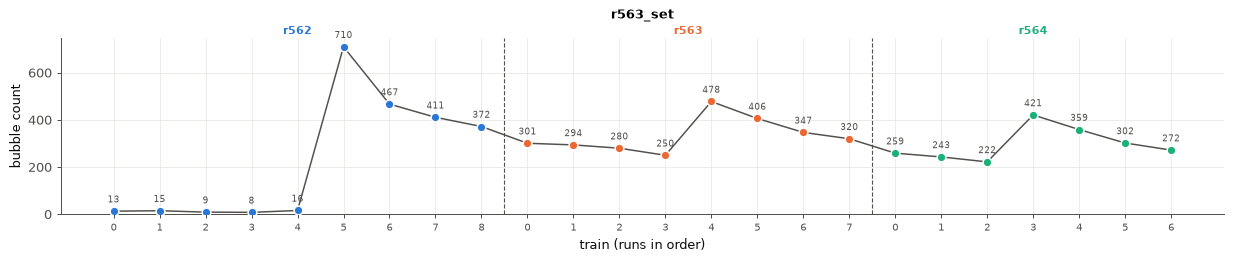

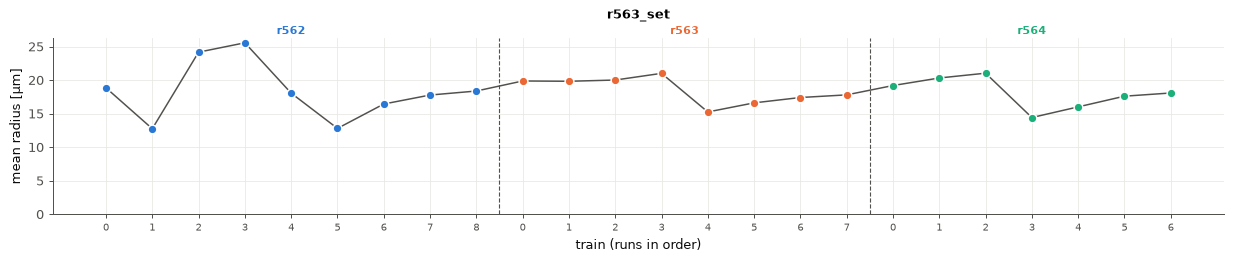

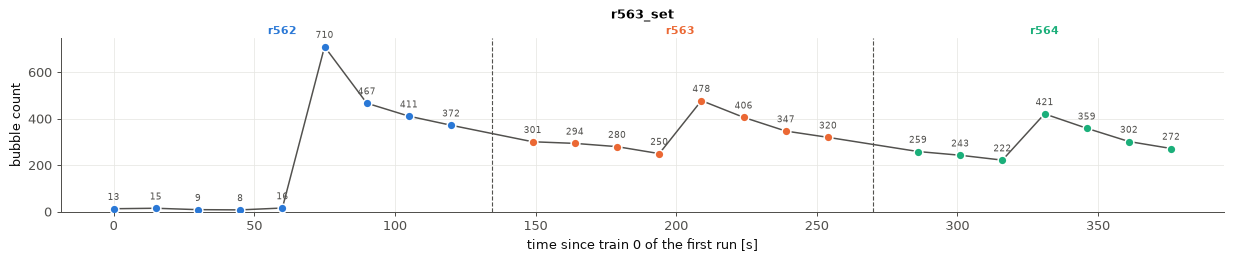

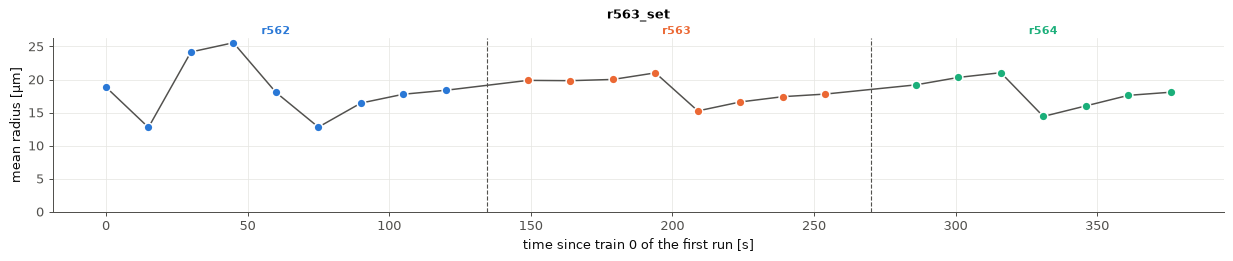

In [4]:
SPECS = [("n_bubbles", "bubble count"), 
         ("r_mean_um", "mean radius [µm]"), 
         # ("r32_um", "Sauter radius r₃₂ [µm]"),
         # ("coverage_frac", "coverage"), 
         # ("area_total_um2", "total bubble area [µm²]"),
         # ("frac_small", f"share r < {SMALL_UM:g} µm"),
        ]
SPECS = [s for s in SPECS if s[0] in m]
fits = pd.concat([bset.fit_decays(m, DECAY_FITS, offset=DECAY_OFFSET, set_name=s) for s in SETS], ignore_index=True) \
    if DECAY_FITS else None
for x in X_AXES:
    fig = bset.plot_timelines(m, SPECS[:1], x=x, fits=fits)
    save(fig, f"timeline_count_{x}")
    fig = bset.plot_timelines(m, SPECS[1:], x=x, annotate_first=False)
    save(fig, f"timeline_other_{x}")

F.clear("Timeline")
for s, g in m.sort_values("seq").groupby("set", sort=False):
    a, b = g.iloc[0], g.iloc[-1]
    i_max, i_min = g["n_bubbles"].idxmax(), g["n_bubbles"].idxmin()
    F.add("Timeline", f"{s}: spans {b.t_s - a.t_s:.0f} s; count {a.n_bubbles:.0f} ({a.run} t{a.train}) → {b.n_bubbles:.0f} ({b.run} t{b.train}), "
          f"×{b.n_bubbles / max(a.n_bubbles, 1):.2f}; max {g.loc[i_max, 'n_bubbles']:.0f} at {g.loc[i_max, 'run']} "
          f"t{g.loc[i_max, 'train']}, min {g.loc[i_min, 'n_bubbles']:.0f} at {g.loc[i_min, 'run']} t{g.loc[i_min, 'train']}")
    F.add("Timeline", f"{s}: mean radius {a.r_mean_um:.1f} → {b.r_mean_um:.1f} µm (×{b.r_mean_um / a.r_mean_um:.2f}), "
          f"r32 {a.r32_um:.1f} → {b.r32_um:.1f} µm, coverage {a.coverage_frac:.2f} → {b.coverage_frac:.2f}, "
          f"total area ×{b.area_total_um2 / a.area_total_um2:.2f}")
    F.add("Timeline", f"{s} count by train: " + " | ".join(
        f"{run}: " + " ".join(f"{v:.0f}" for v in x["n_bubbles"]) for run, x in g.groupby("run", sort=False)))

## 3. Exponential decay after each scan

Each scan adds bubbles; the count then decays. One exponential per entry in `DECAY_FITS`, fitted over the trains
you give (inclusive), with time from the timestamps measured from the first train of the range:
N(t) = N₀·exp(-t/τ) (or with an offset N∞ when `DECAY_OFFSET = True`). τ is the decay time, ln 2·τ the half-life.
The χ² test asks whether all runs share one τ (p < α: they differ by more than the fit uncertainties).

In [5]:
F.clear("Decay fits")
if DECAY_FITS:
    display(fits.round(3))
    fits.to_csv(os.path.join(OUT_DIR, "decay_fits.csv"), index=False)
    fig = bset.plot_decays(m, fits)
    save(fig, "decay_fits")
    for f in fits.itertuples():
        if not np.isfinite(getattr(f, "tau_s", np.nan)):
            F.add("Decay fits", f"{f.set} {f.run} trains {f.first_train}–{f.last_train}: {f.note}")
        else:
            F.add("Decay fits", f"{f.set} {f.run} trains {f.first_train}–{f.last_train} ({f.n_points} pts): "
                  f"N0 = {f.N0:.0f}, τ = {f.tau_s:.0f} ± {f.tau_se:.0f} s (half-life {f.half_life_s:.0f} s)"
                  + (f", N∞ = {f.N_inf:.0f} ± {f.N_inf_se:.0f}" if f.offset else "") + f", R² = {f.r2:.3f}"
                  + (f"  [{f.note}]" if f.note else ""))
    for s in SETS:
        c = bset.compare_taus(fits[fits["set"] == s])
        if c:
            F.add("Decay fits", f"{s} ({c['runs']}): weighted mean τ = {c['tau_weighted_mean']:.0f} ± {c['tau_mean_se']:.0f} s; "
                  f"longest/shortest τ = {c['ratio_max_min']:.2f}; same τ in all runs? χ² = {c['chi2']:.1f} "
                  f"(dof {c['dof']}), {bc.fmt_p(c['p_equal'])} → "
                  + ("τ differs between runs" if c["p_equal"] < ALPHA else "consistent with one τ"))
else:
    print('set DECAY_FITS, e.g. {"r561": (4, 9)}, to fit the decays')

set DECAY_FITS, e.g. {"r561": (4, 9)}, to fit the decays


## 4. Run boundaries

The change from the last train of a run to the first train of the next, compared with the steps between trains
inside the runs. `z` is how unusual the boundary step is (robust z-score of ln ratio): |z| below `BOUNDARY_Z` means
the next run simply continues; larger means a jump at the boundary (a pause between runs, the sample or field of
view moving, a new layer, ...).

In [ ]:
bd = bset.boundaries(m)
bd.to_csv(os.path.join(OUT_DIR, "boundaries.csv"), index=False)
display(bd.round(3))
F.clear("Run boundaries")
for (s, fr, to), g in bd.groupby(["set", "from_run", "to_run"], sort=False):
    parts = [f"gap {g.gap_s.iloc[0]:.0f} s"] if "gap_s" in g and np.isfinite(g.gap_s.iloc[0]) else []
    for r in g.itertuples():
        flag = " JUMP" if np.isfinite(r.z) and abs(r.z) > BOUNDARY_Z else ""
        parts.append(f"{r.metric} ×{r.ratio:.2f} (z {r.z:+.1f}{flag})")
    F.add("Run boundaries", f"{s} {fr} t{g.from_train.iloc[0]} → {to} t{g.to_train.iloc[0]}: " + ", ".join(parts))
if len(bd):
    typ = bd[bd["metric"] == "n_bubbles"]["typical_step"]
    F.add("Run boundaries", "typical count step inside runs: ×" + ", ".join(f"{v:.2f}" for v in typ.unique()) +
          " (median |change| per train)")

## 5. Runs within the set

Each run against its own train number (and time since its train 0), divided by its first train. If the curves lie on top of each other, every
run does the same thing (e.g. the same response to a scan); if not, the state carried over from the previous run
matters.

In [ ]:
for xw in ("train", "t_run_s"):
    fig = bset.plot_relative_runs(m, "n_bubbles", "bubble count", x_within=xw)
    save(fig, f"runs_relative_count_{xw}")
    fig = bset.plot_relative_runs(m, "r_mean_um", "mean radius", x_within=xw)
    save(fig, f"runs_relative_radius_{xw}")
rs = bset.run_summary(m)
display(rs.round(3))
F.clear("Runs within the set")
for r in rs.itertuples():
    F.add("Runs within the set", f"{r.set} {r.run} (trains {r.trains}): count {r.n_bubbles_first:.0f} → "
          f"{r.n_bubbles_last:.0f} (×{r.n_bubbles_last / max(r.n_bubbles_first, 1):.2f}, mean {r.n_bubbles_mean:.0f}), "
          f"mean r {r.r_mean_um_first:.1f} → {r.r_mean_um_last:.1f} µm")

## 6. Size distribution through the set

In [ ]:
for x in X_AXES:
    fig = bset.plot_size_timeline(bubbles, m, x=x)
    save(fig, f"size_timeline_{x}")

## 7. Trends over the whole set

Spearman ρ and a log-linear fit against the position in the set (per train) and against time (per minute), over
all runs together. Run boundaries with a jump (section 3) can dominate a trend, so read it with the
timeline plot.

In [ ]:
m["t_min"] = m["t_s"] / 60
F.clear("Trends over the set")
for xt, unit in (("seq", "train"), ("t_min", "minute")):
  tr = pd.concat([bset.whole_set_trend(m, c, x=xt, log=c not in ("coverage_frac", "frac_small"))
                  for c, _ in SPECS], ignore_index=True)
  display(tr.round(4))
  for r in tr.itertuples():
    sig = "significant" if r.p < ALPHA else "not significant"
    per = f"{r.pct_per_step:+.1f}% per {unit}" if np.isfinite(r.pct_per_step) else f"{r.slope:+.3g} per {unit}"
    F.add("Trends over the set", f"{r.set} {r.metric} vs {unit}: ρ = {r.rho:+.2f} ({bc.fmt_p(r.p)}, {sig}), {per}")

## 8. Findings

Copy the box into the chat. Also saved as `findings.txt` in `OUT_DIR`.

In [ ]:
txt = F.text(f"RUN SETS TIMELINE, frame {FRAME_IDX} | sets {', '.join(SETS)} | trains {TRAIN_SECONDS:g} s apart, "
             f"run starts {RUN_START_S or f'default gap {DEFAULT_RUN_GAP_S:g} s'} | "
             f"{'reviewed only' if REVIEWED_ONLY else 'incl. unreviewed predictions'}")
with open(os.path.join(OUT_DIR, "findings.txt"), "w") as f:
    f.write(txt)
print(txt)

## Your analysis